In [13]:
import matplotlib.pyplot as plt

from sklearn import datasets, metrics
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

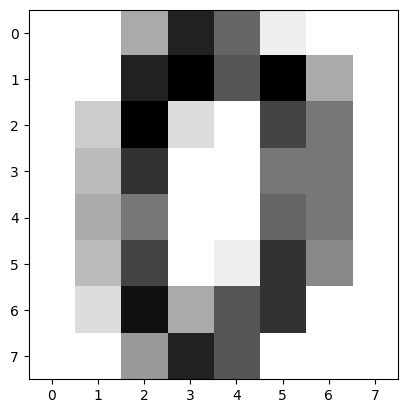

In [14]:
digits = datasets.load_digits()

plt.imshow(
    digits.images[0],
    cmap=plt.cm.gray_r,
    interpolation='nearest'
)

plt.show()

In [15]:
n_samples = len(digits.images)

data = digits.images.reshape((n_samples, -1))

print(data.shape)

(1797, 64)


In [16]:
knn = KNeighborsClassifier(n_neighbors=6)

X_train, X_test, y_train, y_test = train_test_split(
    data,
    digits.target,
    test_size=0.2
)

knn.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=6)

In [24]:
y_pred = knn.predict(X_test)

score_knn = metrics.accuracy_score(y_test, y_pred)

print("KNN 정확도:", score_knn)

KNN 정확도: 0.9916666666666667


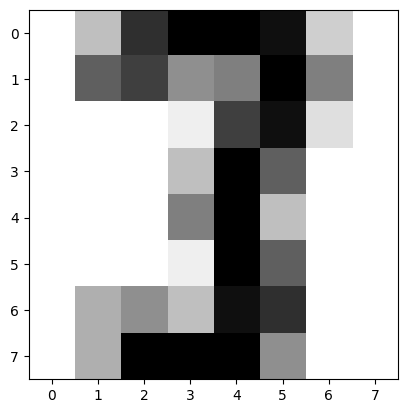

예측 결과: [3]
실제 정답: 3


In [25]:
plt.imshow(
    X_test[10].reshape(8, 8),
    cmap=plt.cm.gray_r,
    interpolation='nearest'
)

plt.show()

y_pred = knn.predict([X_test[10]])

print("예측 결과:", y_pred)
print("실제 정답:", y_test[10])

In [26]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(max_iter=1000)

lr.fit(X_train, y_train)

y_pred_lr = lr.predict(X_test)

score_lr = metrics.accuracy_score(y_test, y_pred_lr)

print("Logistic Regression 정확도:", score_lr)

Logistic Regression 정확도: 0.975


In [27]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier()

dt.fit(X_train, y_train)

y_pred_dt = dt.predict(X_test)

score_dt = metrics.accuracy_score(y_test, y_pred_dt)

print("Decision Tree 정확도:", score_dt)

Decision Tree 정확도: 0.8444444444444444


In [28]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier()

rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

score_rf = metrics.accuracy_score(y_test, y_pred_rf)

print("Random Forest 정확도:", score_rf)

Random Forest 정확도: 0.975


In [29]:
print("KNN:", score_knn)
print("Logistic Regression:", score_lr)
print("Decision Tree:", score_dt)
print("Random Forest:", score_rf)

KNN: 0.9916666666666667
Logistic Regression: 0.975
Decision Tree: 0.8444444444444444
Random Forest: 0.975


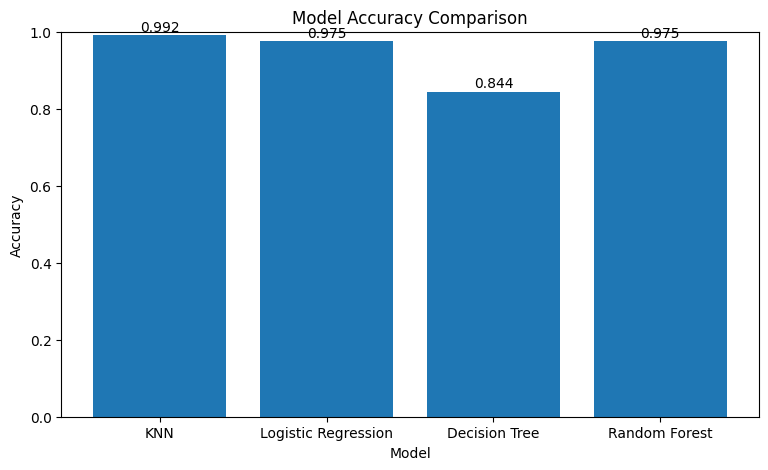

In [30]:
model_names = [
    "KNN",
    "Logistic Regression",
    "Decision Tree",
    "Random Forest"
]

accuracy_scores = [
    score_knn,
    score_lr,
    score_dt,
    score_rf
]

plt.figure(figsize=(9, 5))

plt.bar(model_names, accuracy_scores)

plt.title("Model Accuracy Comparison")
plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.ylim(0, 1)

for i, score in enumerate(accuracy_scores):
    plt.text(i, score + 0.01, f"{score:.3f}", ha="center")

plt.show()